In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

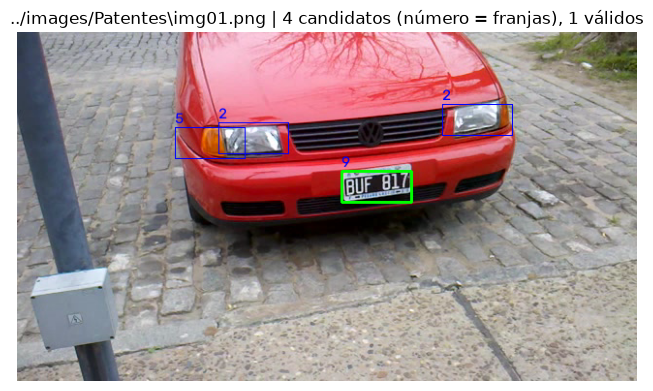

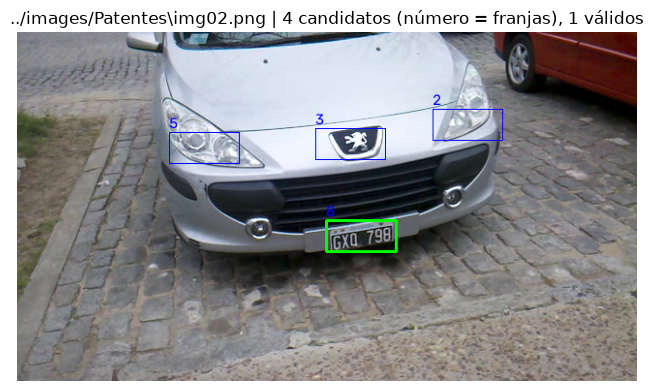

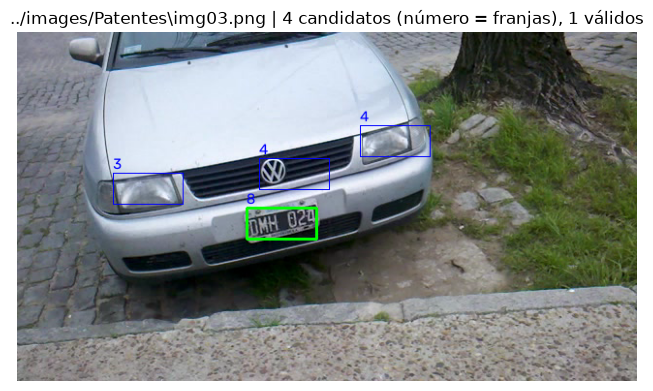

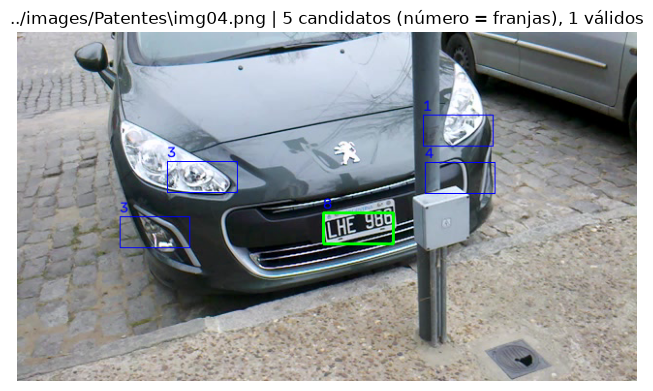

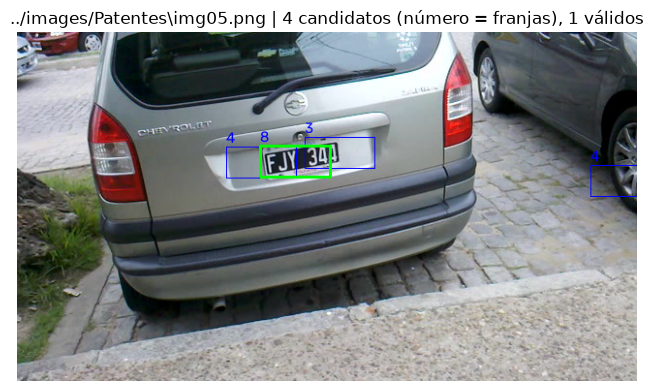

...

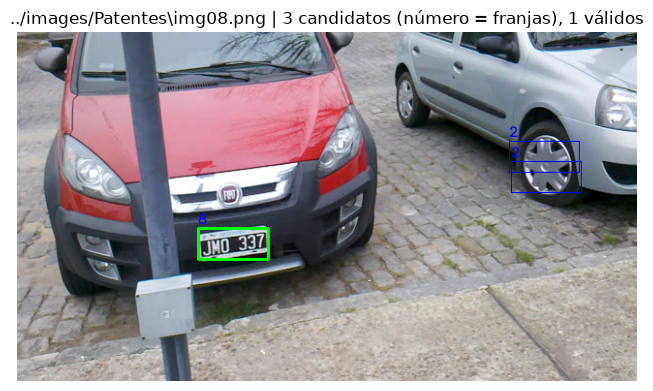

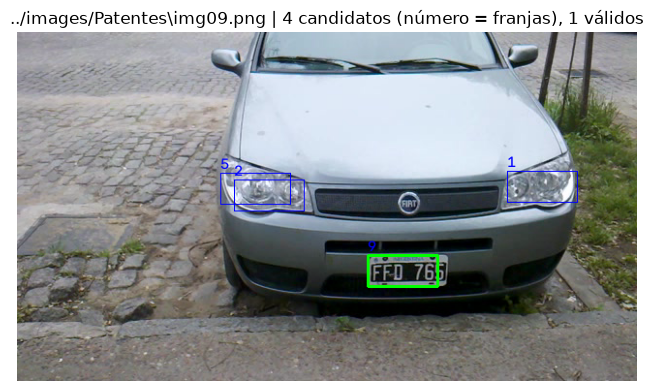

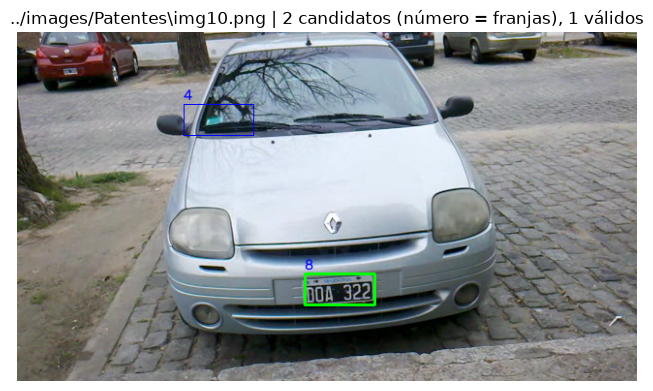

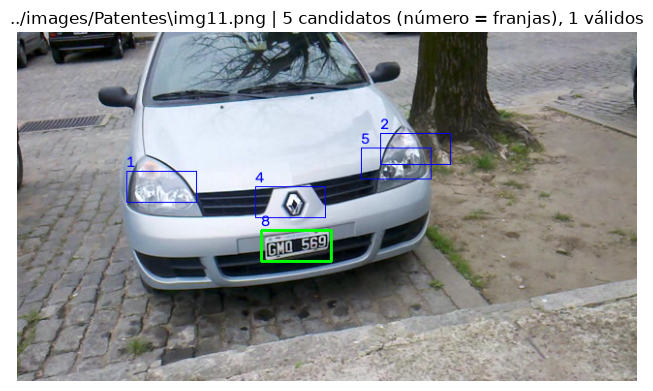

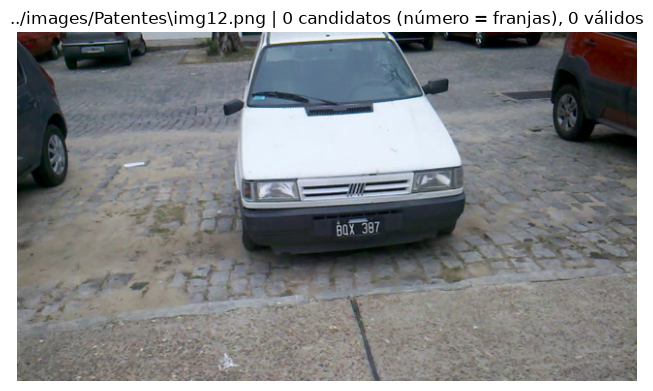

In [45]:
import glob

def contar_corridas(v):
    """Cuenta tramos consecutivos True (de ancho >= 2) en un vector booleano."""
    n, run = 0, 0
    for b in list(v) + [False]:
        if b:
            run += 1
        else:
            if run >= 2:
                n += 1
            run = 0
    return n

def detectar_patente_v4(ruta, W=72, H=32, fraccion_sup=0.25, contraste_min=120,
                        dens_min=0.28, corr_rng=(7, 10), mostrar=True):
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(ruta)
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    h_img, w_img = gris.shape

    # 1) Candidatos: ventanas con muchos bordes verticales y buen contraste (igual que v3)
    sx = cv2.convertScaleAbs(cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3))
    _, bv = cv2.threshold(sx, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    dens = cv2.blur((bv > 0).astype(np.float32), (W, H))
    k = np.ones((H, W), np.uint8)
    contraste = cv2.dilate(gris, k).astype(np.int16) - cv2.erode(gris, k).astype(np.int16)
    score = np.where(contraste >= contraste_min, dens, 0)
    score[:int(fraccion_sup * h_img)] = 0

    n, etiquetas = cv2.connectedComponents((score >= dens_min).astype(np.uint8))
    picos = []
    for i in range(1, n):
        ys, xs = np.where(etiquetas == i)
        j = np.argmax(score[ys, xs])
        cx, cy, s = int(xs[j]), int(ys[j]), float(score[ys[j], xs[j]])
        x0, y0 = max(0, cx - W // 2), max(0, cy - H // 2)
        x1, y1 = min(w_img, cx + W // 2), min(h_img, cy + H // 2)

        # 2) Verificar la estructura: franjas verticales claras en la franja central
        recorte = gris[y0:y1, x0:x1]
        _, b = cv2.threshold(recorte, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        alto = b.shape[0]
        banda = (b[int(0.3 * alto):int(0.7 * alto), :] > 0).mean(axis=0) > 0.5
        picos.append(dict(box=(x0, y0, x1, y1), score=s, corridas=contar_corridas(banda)))

    # 3) Quedan los que tienen la estructura de una patente; entre ellos, el de mayor puntaje
    validos = [p for p in picos if corr_rng[0] <= p['corridas'] <= corr_rng[1]]
    elegido = max(validos, key=lambda p: p['score']) if validos else None

    if mostrar:
        marcada = img.copy()
        for p in picos:
            x0, y0, x1, y1 = p['box']
            cv2.rectangle(marcada, (x0, y0), (x1, y1), (255, 0, 0), 1)
            cv2.putText(marcada, f"{p['corridas']}", (x0, max(12, y0 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
        if elegido:
            x0, y0, x1, y1 = elegido['box']
            cv2.rectangle(marcada, (x0, y0), (x1, y1), (0, 255, 0), 2)
        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(marcada, cv2.COLOR_BGR2RGB))
        plt.title(f'{ruta} | {len(picos)} candidatos (número = franjas), {len(validos)} válidos')
        plt.axis('off')
        plt.show()
    return elegido['box'] if elegido else None

rutas = sorted(glob.glob('../images/Patentes/*.png'))
resultados = {r: detectar_patente_v4(r) for r in rutas}

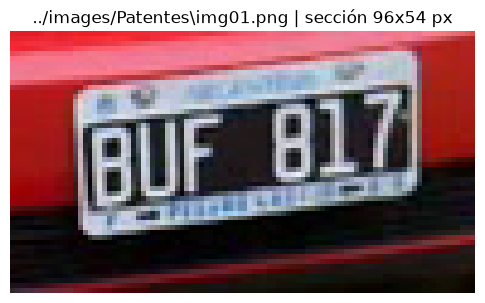

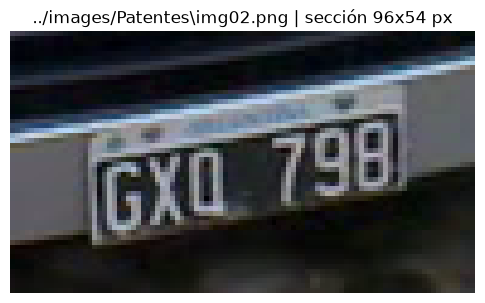

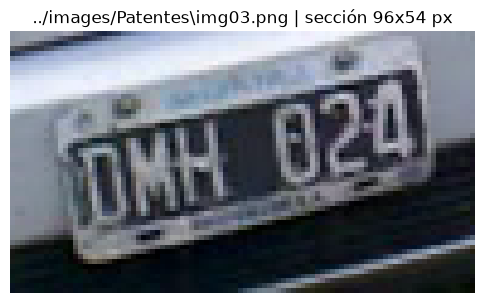

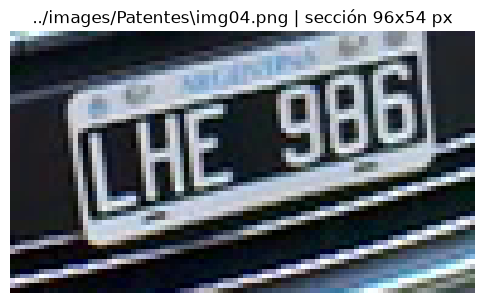

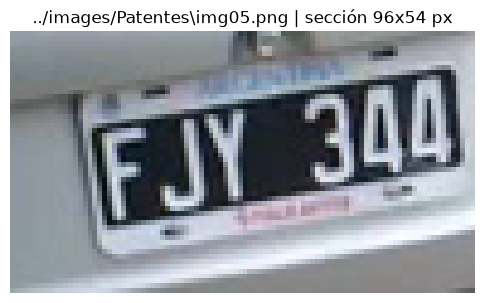

...

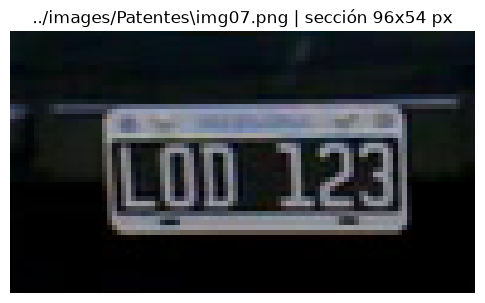

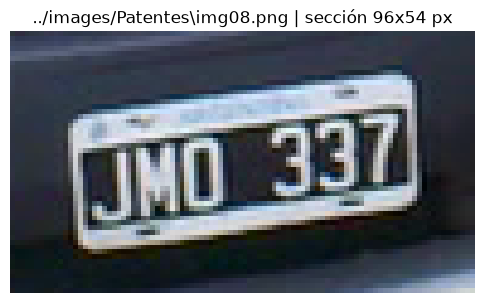

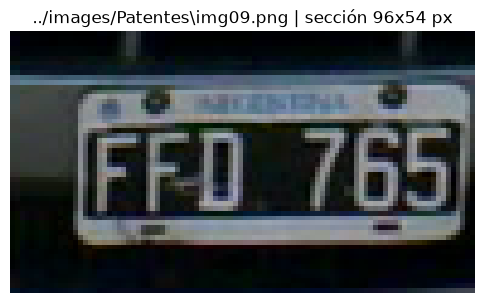

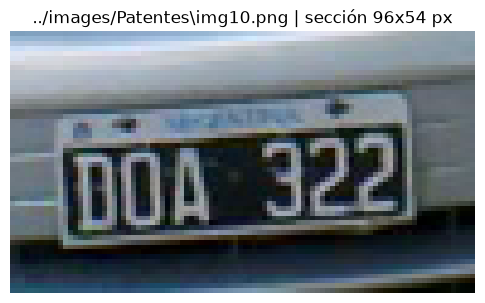

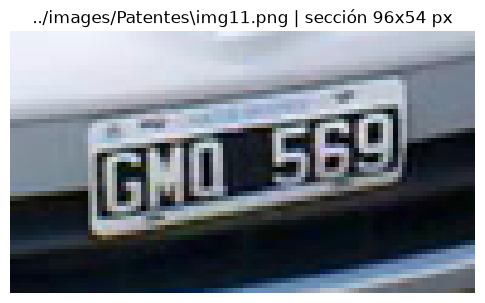

../images/Patentes\img12.png: sin detección, no hay recorte


In [46]:
def recortar_seccion(ruta, box, frac_w=0.15, frac_h=0.15):
    """Recorta una sección de frac_w x frac_h de la imagen, centrada en el centro de `box`."""
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    h_img, w_img = img.shape[:2]
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) // 2, (y0 + y1) // 2                 # centro del rectángulo final
    CW, CH = int(frac_w * w_img), int(frac_h * h_img)       # tamaño de la sección (15% x 15%)

    # Si el recorte se saliera de la imagen, se desplaza (no se achica), para mantener el tamaño
    sx0 = min(max(0, cx - CW // 2), w_img - CW)
    sy0 = min(max(0, cy - CH // 2), h_img - CH)
    return img[sy0:sy0 + CH, sx0:sx0 + CW], (sx0, sy0, sx0 + CW, sy0 + CH)

for ruta, box in resultados.items():
    if box is None:
        print(f'{ruta}: sin detección, no hay recorte')
        continue
    recorte, caja = recortar_seccion(ruta, box)
    plt.figure(figsize=(6, 4))
    plt.imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
    plt.title(f'{ruta} | sección {recorte.shape[1]}x{recorte.shape[0]} px')
    plt.axis('off')
    plt.show()

In [50]:
import cv2, numpy as np
import matplotlib.pyplot as plt

def solo_negro(img, v_max=80, s_max=160):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    negro = (hsv[..., 2] < v_max) & (hsv[..., 1] < s_max)      # oscuro Y poco color
    return negro, np.where(negro[..., None], img, 255).astype(np.uint8)

def mostrar(img, titulo, cmap=None):
    plt.figure(figsize=(8, 4.5))
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(titulo); plt.axis("off"); plt.show()

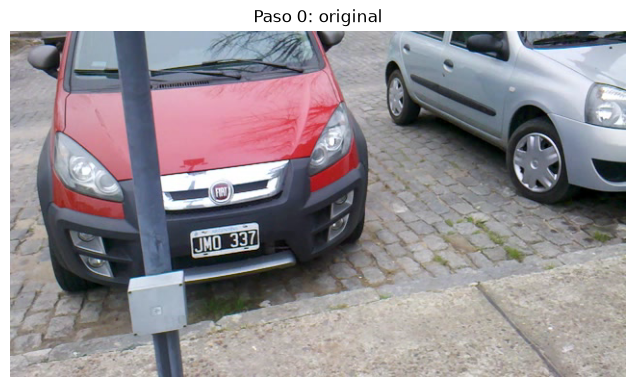

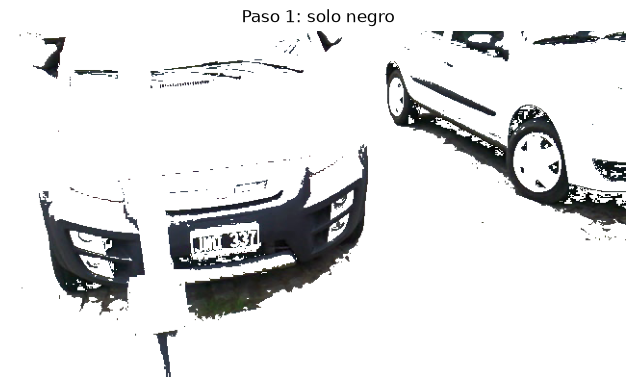

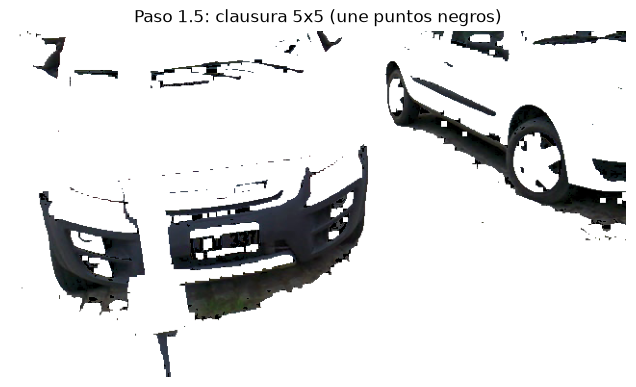

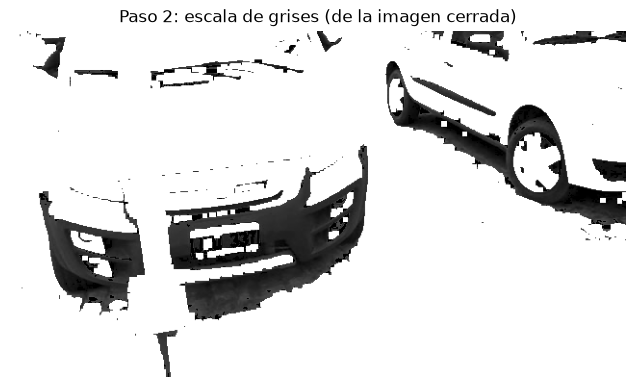

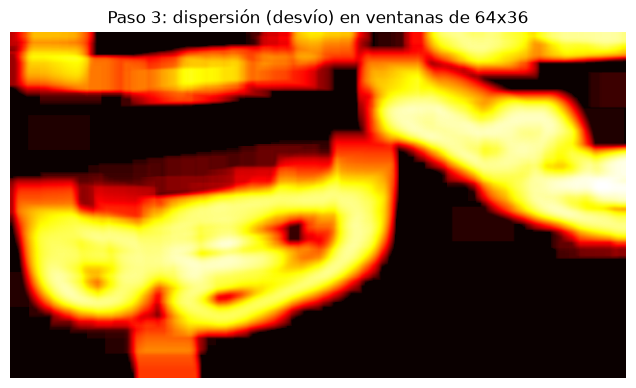

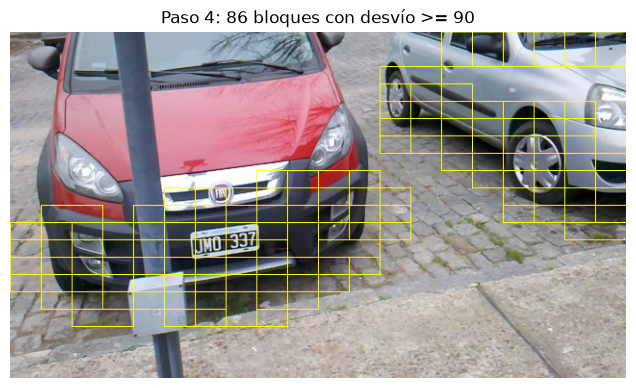

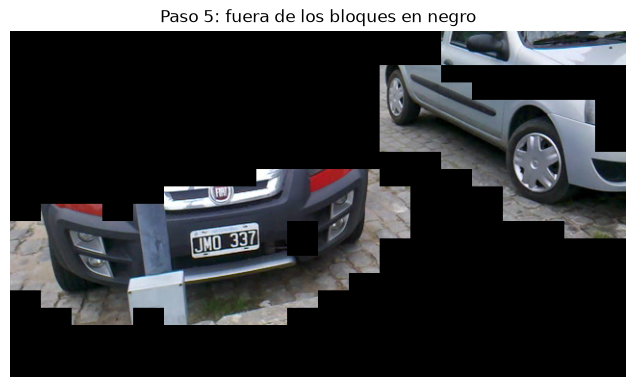

In [57]:
def codigo3(ruta, v_max=80, s_max=160, k_cierre=5, ventana=0.10, paso=0.05, std_min=90):
    img = cv2.imread(ruta, cv2.IMREAD_COLOR)
    h_img, w_img = img.shape[:2]

    # Paso 1: solo negro
    negro, sn = solo_negro(img, v_max, s_max)

    # Paso 1.5: clausura sobre la máscara de negros (une puntos negros cercanos)
    kernel = np.ones((k_cierre, k_cierre), np.uint8)
    cerrado = cv2.morphologyEx(negro.astype(np.uint8), cv2.MORPH_CLOSE, kernel) > 0
    # los píxeles negros originales conservan su color; los que rellenó la clausura van en negro puro
    sn15 = np.where(cerrado[..., None], np.where(negro[..., None], img, 0), 255).astype(np.uint8)

    gris = cv2.cvtColor(sn15, cv2.COLOR_BGR2GRAY).astype(np.float32)

    W, H = int(ventana * w_img), int(ventana * h_img)
    media = cv2.boxFilter(gris, -1, (W, H))
    media2 = cv2.boxFilter(gris * gris, -1, (W, H))
    desvio = np.sqrt(np.maximum(media2 - media ** 2, 0))

    pw, ph = int(paso * w_img), int(paso * h_img)
    bloques = []
    for y0 in range(0, h_img - H + 1, ph):
        for x0 in range(0, w_img - W + 1, pw):
            d = float(desvio[y0 + H // 2, x0 + W // 2])
            if d >= std_min:
                bloques.append((x0, y0, x0 + W, y0 + H, d))

    mascara = np.zeros((h_img, w_img), np.uint8)
    for (x0, y0, x1, y1, d) in bloques:
        cv2.rectangle(mascara, (x0, y0), (x1 - 1, y1 - 1), 255, -1)
    resultado = img.copy()
    resultado[mascara == 0] = 0

    mostrar(img, "Paso 0: original")
    mostrar(sn, "Paso 1: solo negro")
    mostrar(sn15, f"Paso 1.5: clausura {k_cierre}x{k_cierre} (une puntos negros)")
    mostrar(gris, "Paso 2: escala de grises (de la imagen cerrada)")
    mostrar(desvio, f"Paso 3: dispersión (desvío) en ventanas de {W}x{H}", cmap="hot")
    marc = img.copy()
    for (x0, y0, x1, y1, d) in bloques:
        cv2.rectangle(marc, (x0, y0), (x1, y1), (0, 255, 255), 1)
    mostrar(marc, f"Paso 4: {len(bloques)} bloques con desvío >= {std_min}")
    mostrar(resultado, "Paso 5: fuera de los bloques en negro")
    return bloques, resultado

bloques, resultado = codigo3("../images/Patentes/img08.png", k_cierre=5)

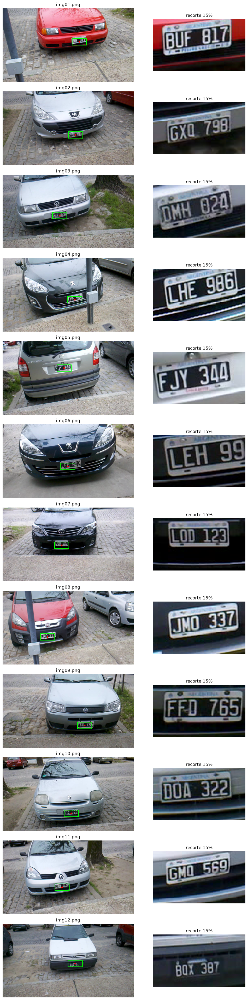

In [61]:
def detectar_punto(img, m_izq=0.20, m_der=0.20, m_sup=0.20, v_max=80, s_max=160, k_limpieza=2,
                   salto=2, ventana_w=0.11, ventana_h=0.09, fraccion_sup=0.25, negro_rng=(0.25, 0.65)):
    h_img, w_img = img.shape[:2]

    # Paso previo: quedarse con la zona central-inferior
    X0, X1, Y0 = int(m_izq * w_img), int((1 - m_der) * w_img), int(m_sup * h_img)
    roi = img[Y0:, X0:X1]

    # El tamaño de ventana sigue siendo % de la imagen ORIGINAL (si no, se achicaría con el recorte)
    W, H = int(ventana_w * w_img), int(ventana_h * h_img)

    negro, _ = solo_negro(roi, v_max, s_max)
    negro = limpiar_claros(negro, k_limpieza)
    t = mapa_transiciones(negro, salto)
    dens = cv2.blur(t.astype(np.float32), (W, H), borderType=cv2.BORDER_CONSTANT)
    frac = cv2.blur(negro.astype(np.float32), (W, H), borderType=cv2.BORDER_CONSTANT)
    puntaje = np.where((frac >= negro_rng[0]) & (frac <= negro_rng[1]), dens, 0)
    puntaje[:max(0, int(fraccion_sup * h_img) - Y0)] = 0     # sigue ignorando el 25% superior original

    cy, cx = np.unravel_index(np.argmax(puntaje), puntaje.shape)
    return int(cx) + X0, int(cy) + Y0, W, H                  # vuelve a coordenadas de la original

def recortar(img, punto, frac=0.15):
    h_img, w_img = img.shape[:2]
    CW, CH = int(frac * w_img), int(frac * h_img)
    x0 = min(max(0, punto[0] - CW // 2), w_img - CW)
    y0 = min(max(0, punto[1] - CH // 2), h_img - CH)
    return img[y0:y0 + CH, x0:x0 + CW]

def ver_todas(rutas):
    n = len(rutas)
    fig, ejes = plt.subplots(n, 2, figsize=(11, 3.2 * n),
                             gridspec_kw={"width_ratios": [2.2, 1]})
    for fila, ruta in zip(ejes, rutas):
        img = cv2.imread(ruta, cv2.IMREAD_COLOR)
        cx, cy, W, H = detectar_punto(img)
        marcada = img.copy()
        cv2.rectangle(marcada, (cx - W // 2, cy - H // 2), (cx + W // 2, cy + H // 2), (0, 255, 0), 2)
        cv2.circle(marcada, (cx, cy), 4, (0, 0, 255), -1)
        fila[0].imshow(cv2.cvtColor(marcada, cv2.COLOR_BGR2RGB))
        fila[0].set_title(ruta[-9:]); fila[0].axis("off")
        fila[1].imshow(cv2.cvtColor(recortar(img, (cx, cy)), cv2.COLOR_BGR2RGB))
        fila[1].set_title("recorte 15%"); fila[1].axis("off")
    plt.tight_layout()
    plt.show()

rutas = [f"../images/Patentes/img{i:02d}.png" for i in range(1, 13)]
ver_todas(rutas)

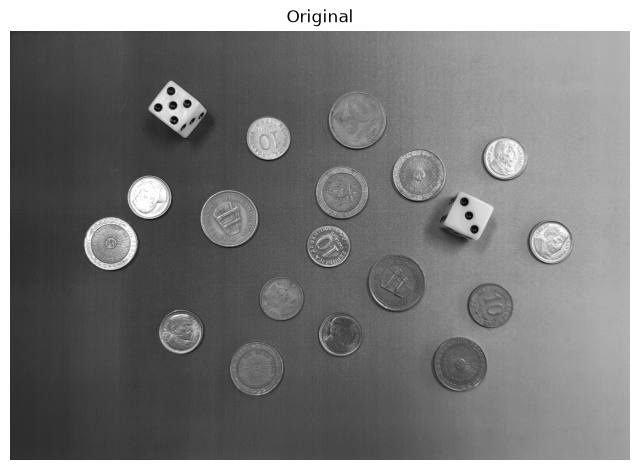

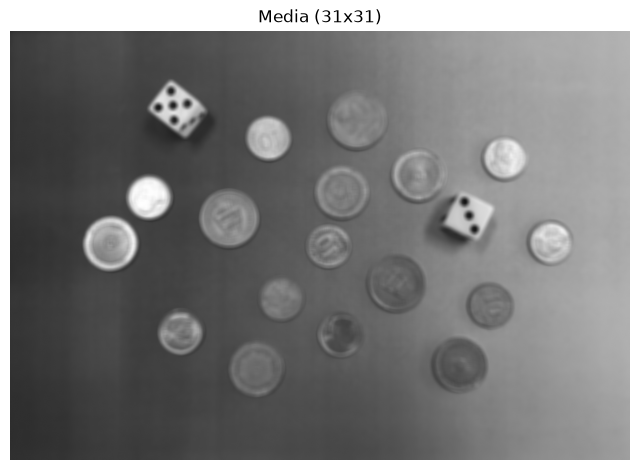

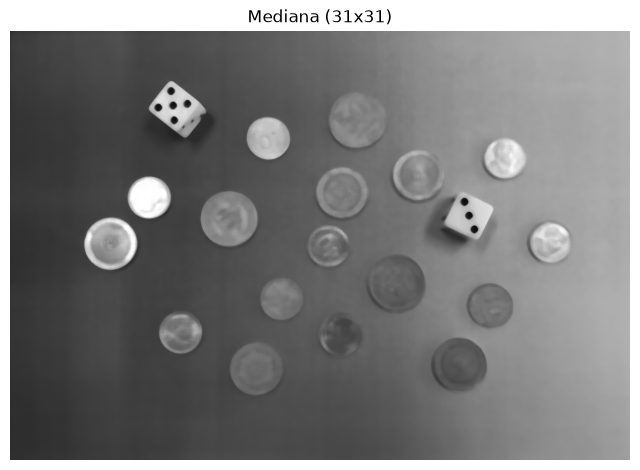

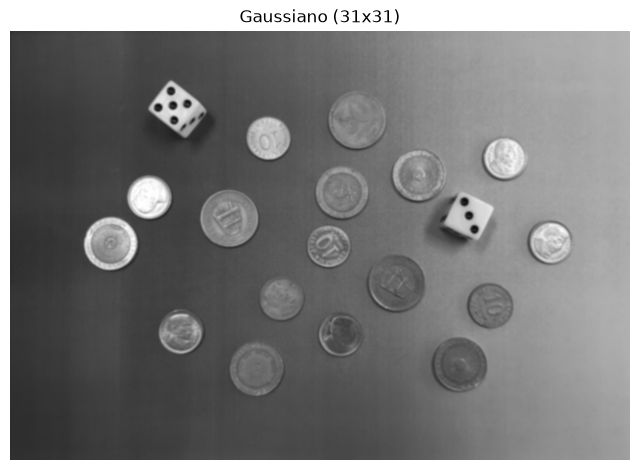

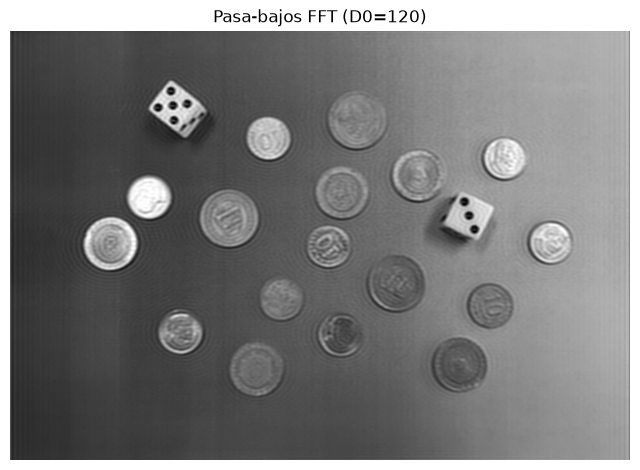

In [5]:
# --- Leer imagen (en escala de grises) ---
img = cv2.imread('../images/monedas.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("No se encontró ../images/monedas.jpg")

# --- Parámetros (para probar) ---
k = 31          # tamaño del kernel (impar) para media, mediana y gaussiano
sigma = 0      # 0 = OpenCV lo calcula a partir de k
D0 = 120        # radio de corte del pasa-bajos en frecuencia (más chico = más suavizado)

# --- Filtros espaciales ---
media    = cv2.blur(img, (k, k))
mediana  = cv2.medianBlur(img, k)
gauss    = cv2.GaussianBlur(img, (k, k), sigma)

# --- Pasa-bajos en frecuencia (filtro ideal circular) ---
def pasa_bajos_fft(imagen, D0):
    F = np.fft.fftshift(np.fft.fft2(imagen))
    filas, cols = imagen.shape
    u, v = np.meshgrid(np.arange(cols) - cols // 2, np.arange(filas) - filas // 2)
    H = (np.sqrt(u**2 + v**2) <= D0).astype(float)   # máscara: 1 dentro del radio, 0 fuera
    resultado = np.fft.ifft2(np.fft.ifftshift(F * H))
    return np.clip(np.abs(resultado), 0, 255).astype(np.uint8)

pasa_bajos = pasa_bajos_fft(img, D0)

# --- Mostrar resultados (una debajo de la otra) ---
imagenes = [img, media, mediana, gauss, pasa_bajos]
titulos  = ['Original', f'Media ({k}x{k})', f'Mediana ({k}x{k})',
            f'Gaussiano ({k}x{k})', f'Pasa-bajos FFT (D0={D0})']

for im, t in zip(imagenes, titulos):
    plt.figure(figsize=(8, 6))
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
    plt.show()

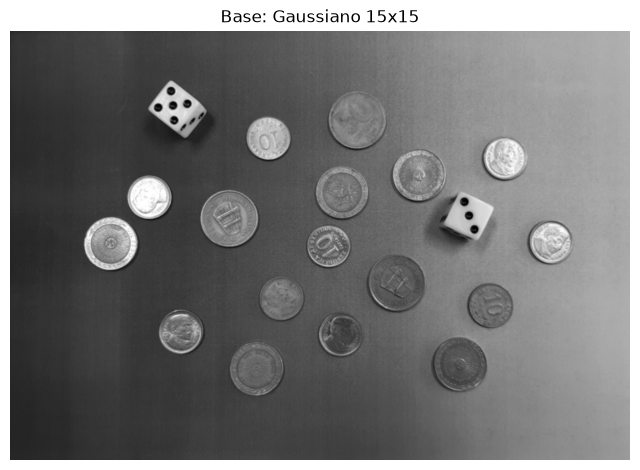

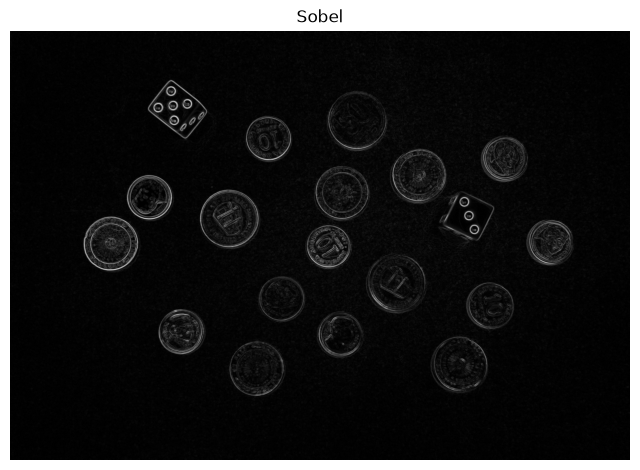

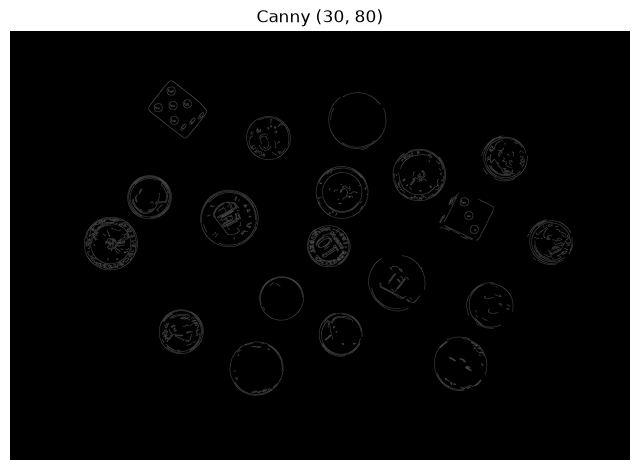

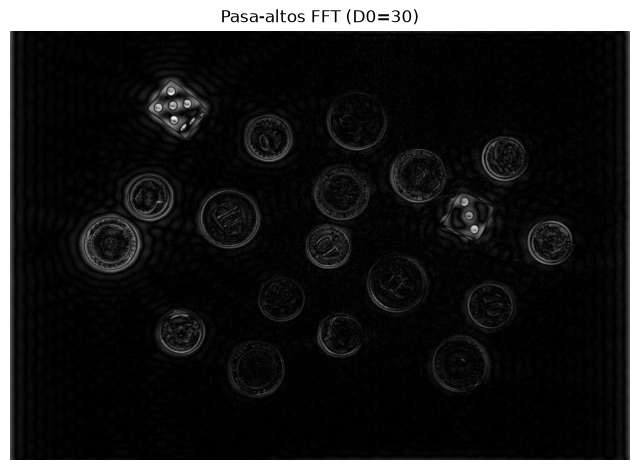

In [40]:
# --- Imagen base: Gaussiano 15x15 ---
base = cv2.GaussianBlur(img, (15, 15), 0)

# --- Sobel (magnitud del gradiente) ---
sobel_x = cv2.Sobel(base, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(base, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(np.sqrt(sobel_x**2 + sobel_y**2))

# --- Canny ---
umbral_bajo, umbral_alto = 30, 80   # para probar
canny = cv2.Canny(base, umbral_bajo, umbral_alto)

# --- Pasa-altos en frecuencia (filtro ideal circular) ---
D0_alto = 30   # radio de corte: se eliminan las frecuencias por debajo de este valor

def pasa_altos_fft(imagen, D0):
    F = np.fft.fftshift(np.fft.fft2(imagen))
    filas, cols = imagen.shape
    u, v = np.meshgrid(np.arange(cols) - cols // 2, np.arange(filas) - filas // 2)
    H = (np.sqrt(u**2 + v**2) > D0).astype(float)   # 0 dentro del radio, 1 fuera
    resultado = np.fft.ifft2(np.fft.ifftshift(F * H))
    return np.clip(np.abs(resultado), 0, 255).astype(np.uint8)

pasa_altos = pasa_altos_fft(base, D0_alto)

# --- Mostrar resultados (una debajo de la otra) ---
imagenes = [base, sobel, canny, pasa_altos]
titulos  = ['Base: Gaussiano 15x15', 'Sobel', f'Canny ({umbral_bajo}, {umbral_alto})',
            f'Pasa-altos FFT (D0={D0_alto})']

for im, t in zip(imagenes, titulos):
    plt.figure(figsize=(8, 6))
    plt.imshow(im, cmap='gray')
    plt.title(t)
    plt.axis('off')
    plt.show()

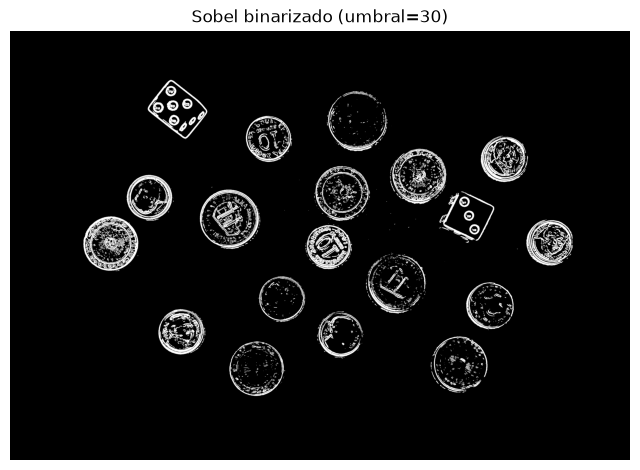

In [18]:
# --- Binarización con umbral 127 ---
umbral = 30
_, binaria = cv2.threshold(sobel, umbral, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(8, 6))
plt.imshow(binaria, cmap='gray', vmin=0, vmax=255)
plt.title(f'Sobel binarizado (umbral={umbral})')
plt.axis('off')
plt.show()

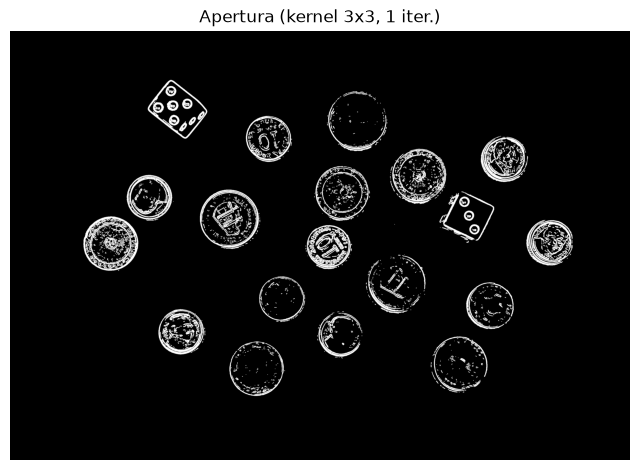

In [32]:
# --- Dilatación ---
k_morf = 3                                   # tamaño del kernel (para probar)
kernel = np.ones((k_morf, k_morf), np.uint8)
iteraciones = 1

# --- Apertura ---
apertura = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel, iterations=iteraciones)

plt.figure(figsize=(8, 6))
plt.imshow(apertura, cmap='gray', vmin=0, vmax=255)
plt.title(f'Apertura (kernel {k_morf}x{k_morf}, {iteraciones} iter.)')
plt.axis('off')
plt.show()

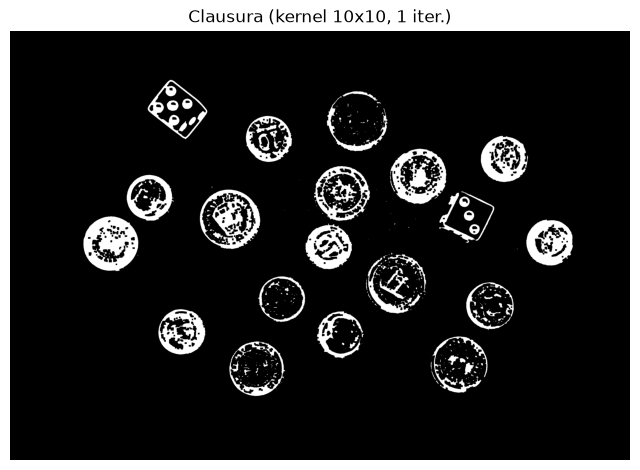

In [38]:
k_morf = 10
# --- Clausura ---
clausura = cv2.morphologyEx(binaria, cv2.MORPH_CLOSE, kernel, iterations=4)

plt.figure(figsize=(8, 6))
plt.imshow(clausura, cmap='gray', vmin=0, vmax=255)
plt.title(f'Clausura (kernel {k_morf}x{k_morf}, {iteraciones} iter.)')
plt.axis('off')
plt.show()

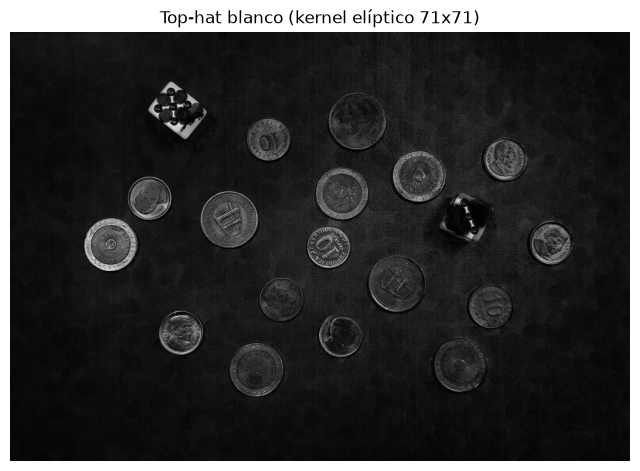

In [42]:
# --- Top-hat blanco: original - apertura (detalles claros y chicos) ---
k_th = 71   # el kernel debe ser MÁS GRANDE que los objetos a conservar
kernel_th = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_th, k_th))

tophat_blanco = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel_th)

plt.figure(figsize=(8, 6))
plt.imshow(tophat_blanco, cmap='gray')
plt.title(f'Top-hat blanco (kernel elíptico {k_th}x{k_th})')
plt.axis('off')
plt.show()

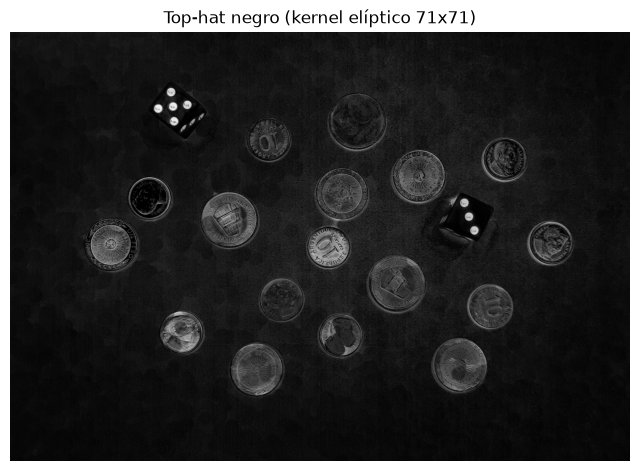

In [43]:
# --- Top-hat negro: clausura - original (detalles oscuros y chicos) ---
tophat_negro = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel_th)

plt.figure(figsize=(8, 6))
plt.imshow(tophat_negro, cmap='gray')
plt.title(f'Top-hat negro (kernel elíptico {k_th}x{k_th})')
plt.axis('off')
plt.show()

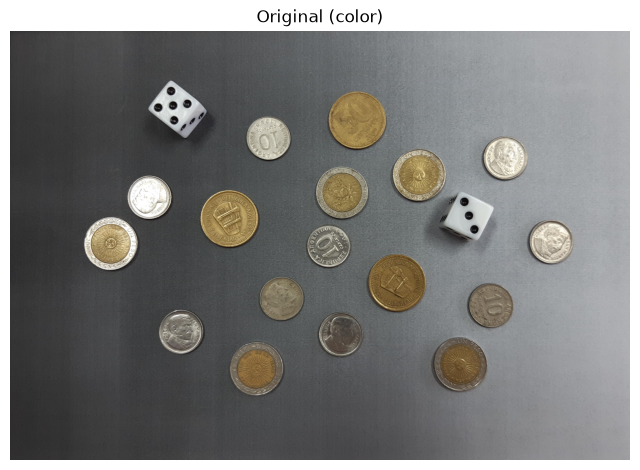

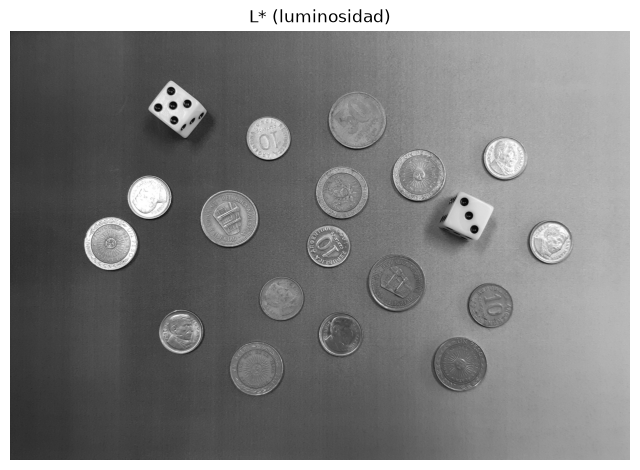

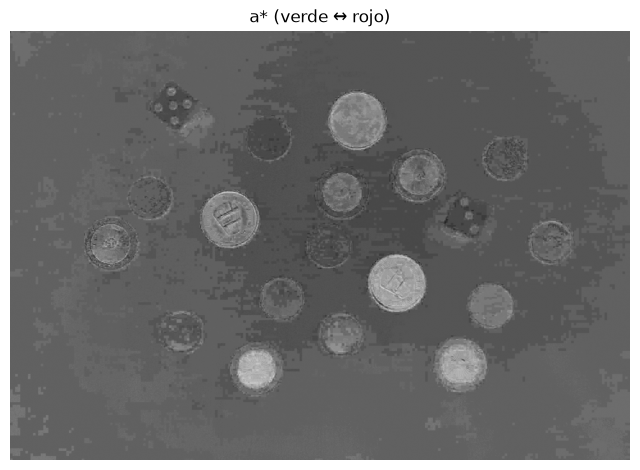

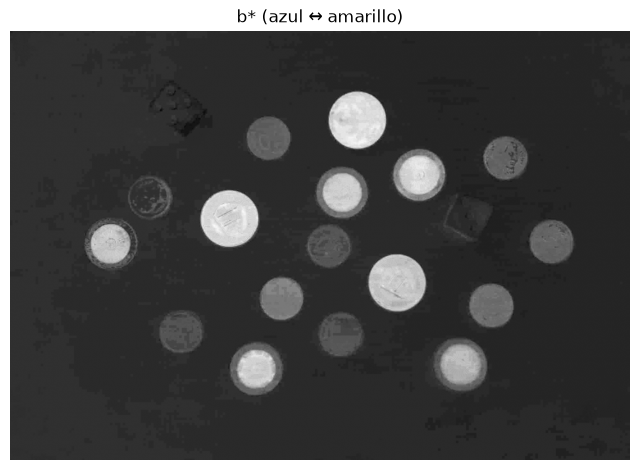

In [44]:
# --- Leer en color y pasar a CIELAB ---
img_color = cv2.imread('../images/monedas.jpg', cv2.IMREAD_COLOR)   # BGR
lab = cv2.cvtColor(img_color, cv2.COLOR_BGR2LAB)
L, a, b = cv2.split(lab)

# --- Mostrar (una debajo de la otra) ---
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))   # matplotlib espera RGB
plt.title('Original (color)')
plt.axis('off')
plt.show()

for canal, t in zip([L, a, b], ['L* (luminosidad)', 'a* (verde ↔ rojo)', 'b* (azul ↔ amarillo)']):
    plt.figure(figsize=(8, 6))
    plt.imshow(canal, cmap='gray')
    plt.title(t)
    plt.axis('off')
    plt.show()

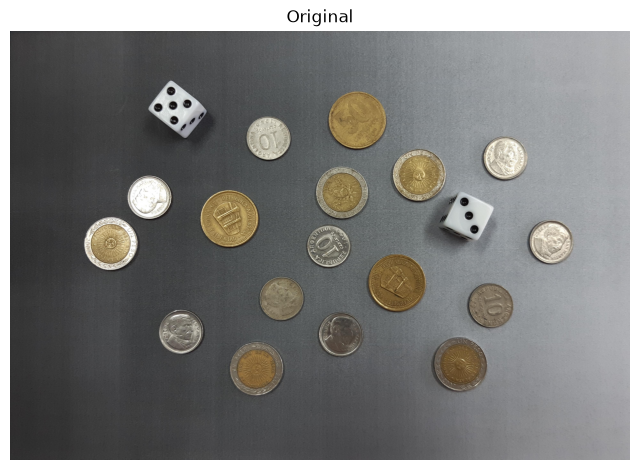

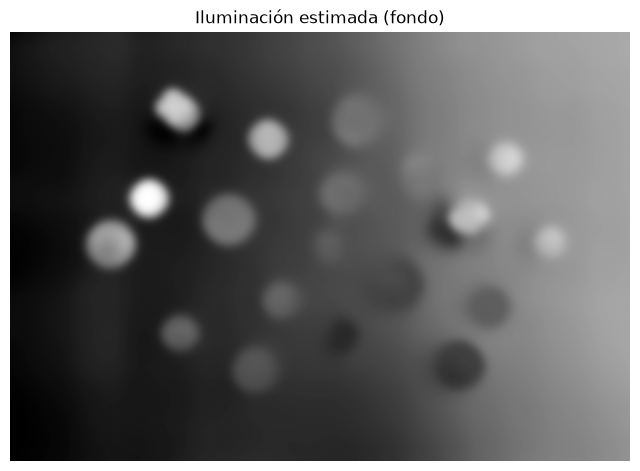

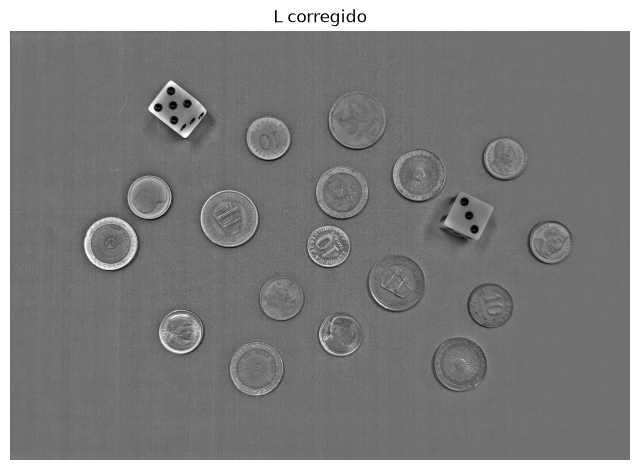

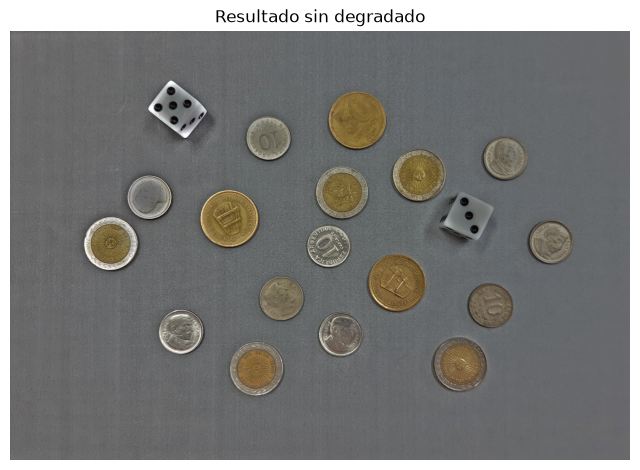

In [45]:
# --- Corrección de iluminación en el canal L ---
k_fondo = 151   # impar y MUY grande, mayor que las monedas, para que no las incluya

# 1) Estimar la iluminación del fondo
L_f = L.astype(np.float32)
fondo = cv2.medianBlur(L, k_fondo).astype(np.float32)
fondo = cv2.GaussianBlur(fondo, (0, 0), k_fondo / 6)   # suaviza más el resultado

# 2) Quitar el degradado (modelo multiplicativo) y mantener el brillo promedio
L_corr = L_f / (fondo + 1e-6) * fondo.mean()
L_corr = np.clip(L_corr, 0, 255).astype(np.uint8)

# 3) Reunir con a, b y volver a BGR
lab_corr = cv2.merge([L_corr, a, b])
img_corr = cv2.cvtColor(lab_corr, cv2.COLOR_LAB2BGR)

# --- Mostrar (una debajo de la otra) ---
imagenes = [cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB),
            fondo.astype(np.uint8),
            L_corr,
            cv2.cvtColor(img_corr, cv2.COLOR_BGR2RGB)]
titulos  = ['Original', 'Iluminación estimada (fondo)', 'L corregido', 'Resultado sin degradado']

for im, t in zip(imagenes, titulos):
    plt.figure(figsize=(8, 6))
    plt.imshow(im, cmap='gray' if im.ndim == 2 else None)
    plt.title(t)
    plt.axis('off')
    plt.show()

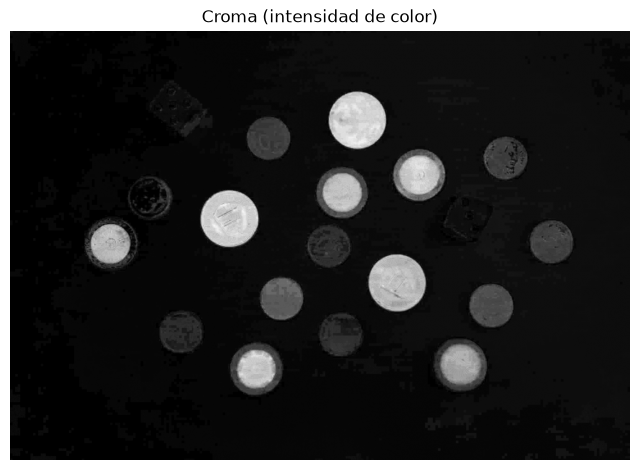

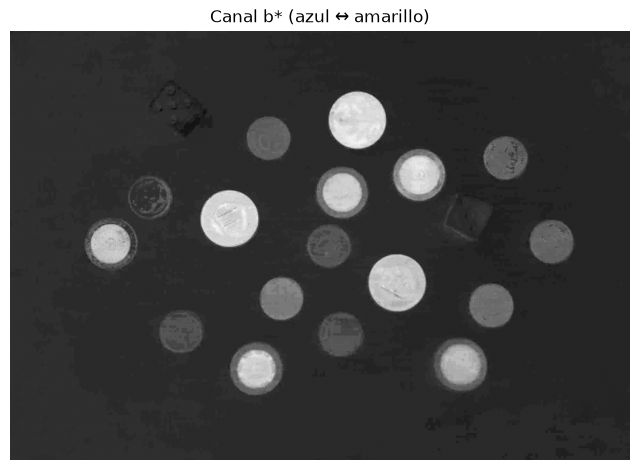

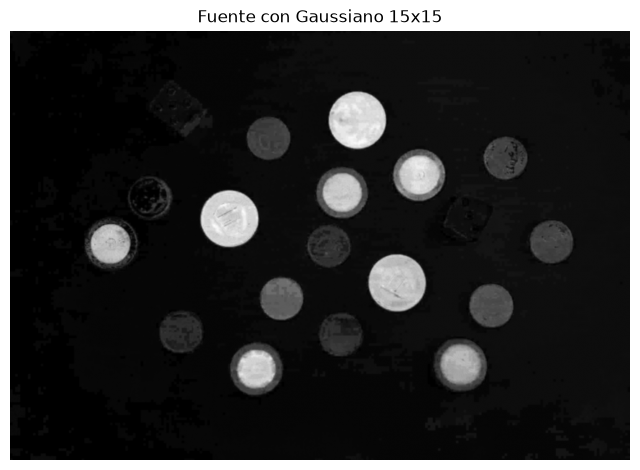

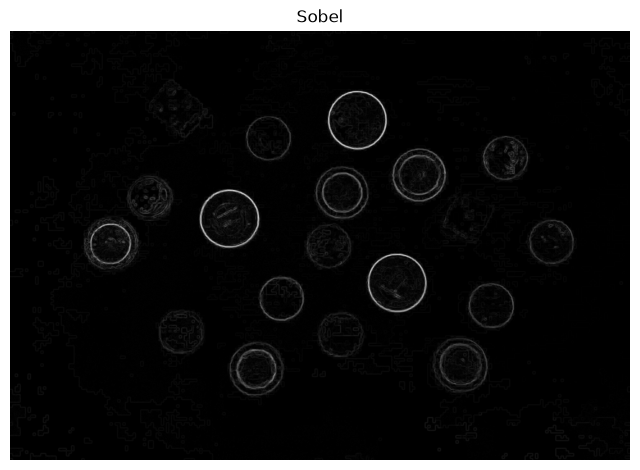

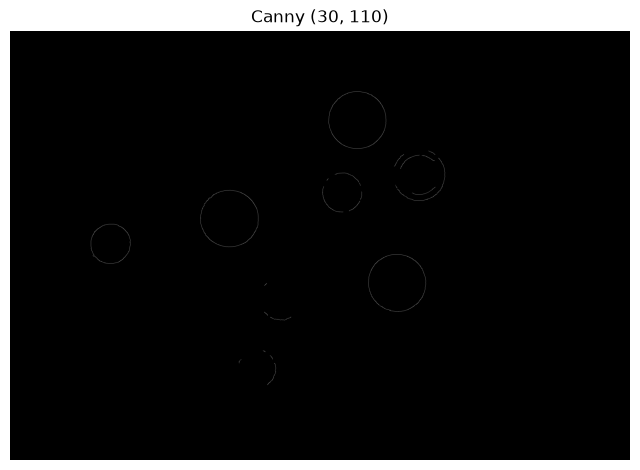

In [52]:
# --- Mapa de color a partir de a* y b* (128 = neutro/gris) ---
a_f = a.astype(np.float32) - 128
b_f = b.astype(np.float32) - 128

croma = np.sqrt(a_f**2 + b_f**2)                                   # intensidad del color
croma = cv2.normalize(croma, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)   # estirar contraste

b_canal = cv2.normalize(b_f, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)   # solo azul↔amarillo

# --- Elegir sobre cuál trabajar ---
fuente = croma        # cambiá a b_canal para usar solo b*

# --- Gaussiano ---
k_g = 15
fuente_gauss = cv2.GaussianBlur(fuente, (k_g, k_g), 0)

# --- Sobel ---
sx = cv2.Sobel(fuente_gauss, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(fuente_gauss, cv2.CV_64F, 0, 1, ksize=3)
sobel_color = cv2.convertScaleAbs(np.sqrt(sx**2 + sy**2))

# --- Canny ---
umbral_bajo, umbral_alto = 30, 110
canny_color = cv2.Canny(fuente_gauss, umbral_bajo, umbral_alto)

# --- Mostrar (una debajo de la otra) ---
imagenes = [croma, b_canal, fuente_gauss, sobel_color, canny_color]
titulos  = ['Croma (intensidad de color)', 'Canal b* (azul ↔ amarillo)',
            f'Fuente con Gaussiano {k_g}x{k_g}', 'Sobel', f'Canny ({umbral_bajo}, {umbral_alto})']

for im, t in zip(imagenes, titulos):
    plt.figure(figsize=(8, 6))
    plt.imshow(im, cmap='gray')
    plt.title(t)
    plt.axis('off')
    plt.show()

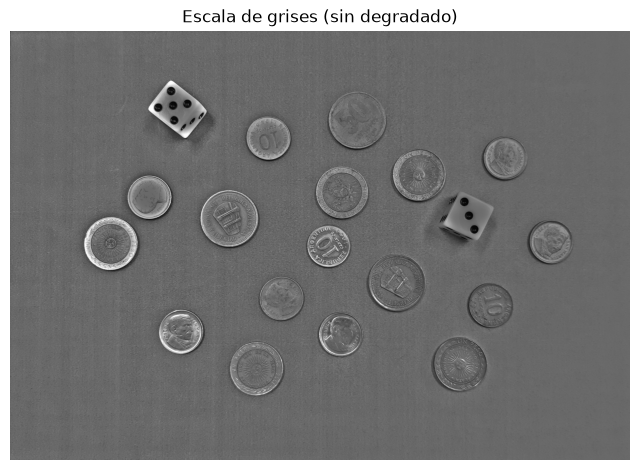

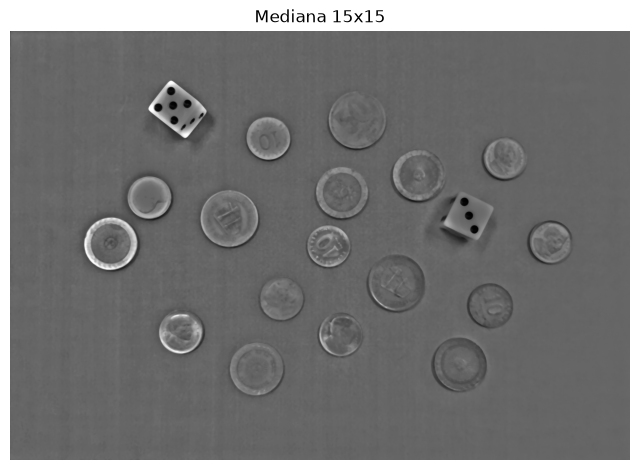

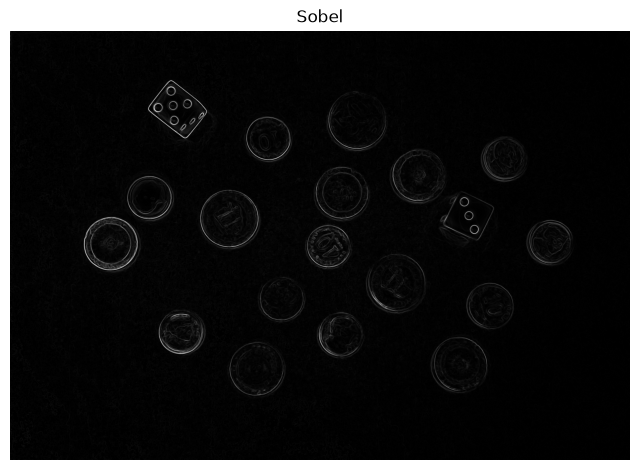

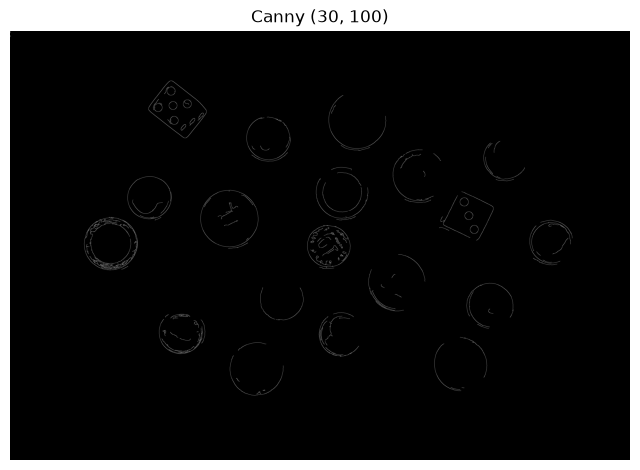

In [54]:
# --- 1) Escala de grises del resultado sin degradado ---
gris_corr = cv2.cvtColor(img_corr, cv2.COLOR_BGR2GRAY)

# --- 2) Filtro gaussiano ---
k_g = 15   # tamaño del kernel (impar), para probar
gris_gauss = cv2.medianBlur(gris_corr, k_g, 0)

# --- 3a) Sobel (magnitud del gradiente) ---
sx = cv2.Sobel(gris_gauss, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gris_gauss, cv2.CV_64F, 0, 1, ksize=3)
sobel_corr = cv2.convertScaleAbs(np.sqrt(sx**2 + sy**2))

# --- 3b) Canny ---
umbral_bajo, umbral_alto = 30, 100   # para probar
canny_corr = cv2.Canny(gris_gauss, umbral_bajo, umbral_alto)

# --- Mostrar (una debajo de la otra) ---
imagenes = [gris_corr, gris_gauss, sobel_corr, canny_corr]
titulos  = ['Escala de grises (sin degradado)',
            f'Mediana {k_g}x{k_g}',
            'Sobel',
            f'Canny ({umbral_bajo}, {umbral_alto})']

for im, t in zip(imagenes, titulos):
    plt.figure(figsize=(8, 6))
    plt.imshow(im, cmap='gray')
    plt.title(t)
    plt.axis('off')
    plt.show()

In [2]:
# ==========================================
# 1. Definición de la función de ecualización local
# ==========================================
def ecualizacion_local_histograma(img, ksize=(15, 15)):
    """
    Realiza la ecualización local del histograma pixel a pixel.

    img: numpy array 2D (uint8)
    ksize: tupla (M, N) tamaño de la ventana
    """
    M, N = ksize
    pad_y = M // 2
    pad_x = N // 2

    # Agregar borde
    img_padded = cv2.copyMakeBorder(
        img,
        top=pad_y,
        bottom=pad_y,
        left=pad_x,
        right=pad_x,
        borderType=cv2.BORDER_REPLICATE
    )

    alto, ancho = img.shape
    img_salida = np.zeros((alto, ancho), dtype=np.uint8)
    total_pixeles = M * N

    # Recorrido pixel a pixel
    for i in range(alto):
        for j in range(ancho):

            # Extraer el vecindario local MxN
            vecindario = img_padded[i:i + M, j:j + N]

            # Histograma del vecindario
            histograma = cv2.calcHist(
                [vecindario],
                [0],
                None,
                [256],
                [0, 256]
            ).flatten()

            # Frecuencia acumulada (CDF)
            cdf = (histograma / total_pixeles).cumsum()

            # Valor del píxel central
            val_central = img[i, j]

            # Aplicar transformación de ecualización
            nuevo_val = np.round(255 * cdf[val_central])

            img_salida[i, j] = nuevo_val

    return img_salida

In [5]:
# ==========================================
# 2. Carga y procesamiento de la imagen
# ==========================================
ruta_imagen = '../images/monedas.jpg'
img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)

# Ecualización local con kernel de 30x30
img_loc_30 = ecualizacion_local_histograma(img, (30, 30))

# ==========================================
# 3. Visualización y Comparación
# ==========================================
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axs[0].set_title('Imagen Original')
axs[0].axis('off')

axs[1].imshow(img_loc_30, cmap='gray', vmin=0, vmax=255)
axs[1].set_title('Ecualización Local (30x30)')
axs[1].axis('off')

plt.tight_layout()

plt.savefig(
    '../images/output/problema_1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

KeyboardInterrupt: 